# Разведочный анализ данных

Ищем аномалии в данных Default of Credit Card Clients и решаем, как их чистить, какие правила валидации задать и какие признаки добавить.

## 1. Импорты

Исследование проводили до автоматизации. Потом код очистки и признаков перенесли в src для пайплайна, поэтому здесь используем те же функции.

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.append("..")
import src.data.make_dataset as make_dataset
import src.features.build_features as build_features

plt.rcParams.update({
    "figure.facecolor": "none",
    "axes.facecolor": "none",
    "text.color": "gray",
    "axes.labelcolor": "gray",
    "axes.edgecolor": "gray",
    "xtick.color": "gray",
    "ytick.color": "gray"
})

## 2. Загрузка данных

In [2]:
raw = pd.read_csv("../data/raw/UCI_Credit_Card.csv")
raw.shape

(30000, 25)

## 3. Просмотр данных

In [3]:
raw.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


В таблице 30000 строк и 25 столбцов.

Проверяем типы столбцов и NaN.

In [4]:
print(raw.dtypes.value_counts().to_string())
print("NaN во всей таблице:", raw.isna().sum().sum())

float64    13
int64      12
NaN во всей таблице: 0


Все столбцы числовые, NaN нет. В правилах валидации требуем числовые типы и отсутствие NaN.

## 4. Анализ и очистка

Проверяем уникальность ID и ищем повторяющиеся строки без учёта ID.

In [5]:
print("ID уникален:", raw["ID"].is_unique)
print("Дубликатов без учёта ID:", raw.drop(columns="ID").duplicated().sum())
duplicates = raw[raw.drop(columns="ID").duplicated(keep=False)]
print("Строк, участвующих в дубликатах:", len(duplicates))
print("Из них с нулевыми счетами за все месяцы:", (duplicates[build_features.BILL_AMT] == 0).all(axis=1).sum())

ID уникален: True
Дубликатов без учёта ID: 35
Строк, участвующих в дубликатах: 70
Из них с нулевыми счетами за все месяцы: 60


ID уникален. Без учёта ID есть 35 пар одинаковых строк, у 60 из этих 70 строк счета нулевые за все шесть месяцев. ID у них разные, поэтому строки не удаляем.

По описанию датасета на Kaggle EDUCATION принимает значения 1–6, где 5 и 6 — unknown, MARRIAGE — 1–3, SEX — 1 и 2. Смотрим, какие значения есть в данных.

In [6]:
for column in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(column, raw[column].value_counts().sort_index().to_dict())

SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}


Кроме описанных, в EDUCATION и MARRIAGE встречается код 0: у 14 и 54 клиентов.

Смотрим долю клиентов с дефолтом (ключевой переменной default.payment.next.month = 1) по кодам EDUCATION.

In [7]:
raw.groupby("EDUCATION")[make_dataset.RAW_TARGET].agg(["mean", "size"]).round(3)

,mean,size
EDUCATION,,
0,0.000,14
1,0.192,10585
2,0.237,14030
3,0.252,4917
4,0.057,123
5,0.064,280
6,0.157,51


У кодов 0, 4, 5 и 6 доля клиентов с дефолтом от 0.0 до 0.157, у кодов 1–3 — от 0.192 до 0.252. Коды 0, 5 и 6 не несут информации об образовании (0 нет в описании, 5 и 6 — unknown) и встречаются редко, поэтому объединяем их с 4 (others). Правила валидации проверяют сырые данные и допускают EDUCATION от 0 до 6, а API принимает только 1–4.

PAY_0, PAY_2–PAY_6 — статусы платежа за шесть месяцев. По описанию -1 — оплата вовремя, 1–9 — месяцы просрочки. Значения -2 и 0 в описании нет, их считаем платежом без просрочки: в признаках просрочкой считаем только положительные значения. PAY_1 в датасете нет. Смотрим диапазон значений.

In [8]:
raw[build_features.PAY_STATUS].agg(["min", "max"])

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
min,-2,-2,-2,-2,-2,-2
max,8,8,8,8,8,8


Значения от -2 до 8. В правилах берём диапазон от -2 до 9: по описанию датасета 9 — просрочка от девяти месяцев.

Проверяем знак сумм счетов и платежей.

In [9]:
pd.DataFrame(
    {
        "отрицательных счетов": (raw[build_features.BILL_AMT] < 0).sum().values,
        "отрицательных платежей": (raw[build_features.PAY_AMT] < 0).sum().values
    },
    index=range(1, 7)
)

,отрицательных счетов,отрицательных платежей
1,590,0
2,669,0
3,655,0
4,675,0
5,655,0
6,688,0


Отрицательные счета есть в каждом месяце, их оставляем. Отрицательных платежей нет, поэтому в правилах требуем PAY_AMT не меньше нуля.

Чистим данные: удаляем ID, переименовываем целевую переменную в default и объединяем коды EDUCATION 0, 5, 6 с 4, а MARRIAGE 0 — с 3. Таблица raw не меняется.

In [10]:
data = make_dataset.clean_data(raw)
for column in ["EDUCATION", "MARRIAGE"]:
    print(column, data[column].value_counts().sort_index().to_dict())

EDUCATION {1: 10585, 2: 14030, 3: 4917, 4: 468}
MARRIAGE {1: 13659, 2: 15964, 3: 377}


После очистки в EDUCATION остались коды 1–4, в MARRIAGE — 1–3.

## 5. EDA

Смотрим баланс классов.

In [11]:
data["default"].value_counts(normalize=True).to_frame()

,proportion
default,
0,0.7788
1,0.2212


Дефолт у 22.1% клиентов, классы несбалансированы. Поэтому делим выборку со стратификацией, модели сравниваем по ROC-AUC, она не зависит от порога, а порог подбираем по F1.

Смотрим долю клиентов с дефолтом по статусу последнего платежа PAY_0.

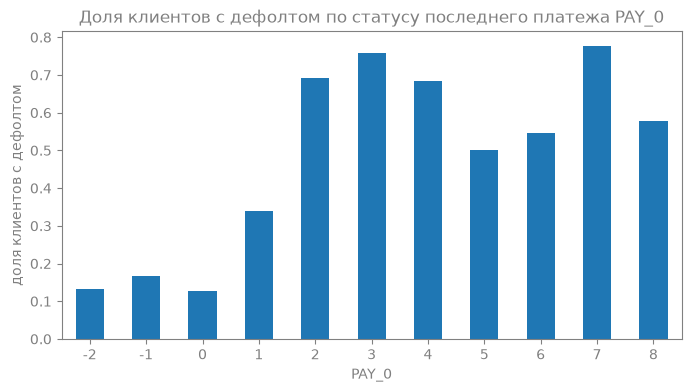

PAY_0,-2,-1,0,1,2,3,4,5,6,7,8
mean,0.132,0.168,0.128,0.339,0.691,0.758,0.684,0.5,0.545,0.778,0.579
size,2759.000,5686.000,14737.000,3688.000,2667.000,322.000,76.000,26.0,11.000,9.000,19.000


In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
data.groupby("PAY_0")["default"].mean().plot.bar(ax=ax, rot=0)
ax.set_title("Доля клиентов с дефолтом по статусу последнего платежа PAY_0")
ax.set_xlabel("PAY_0")
ax.set_ylabel("доля клиентов с дефолтом")
plt.show()
data.groupby("PAY_0")["default"].agg(["mean", "size"]).T.round(3)

При PAY_0 от -2 до 0 доля клиентов с дефолтом от 0.128 до 0.168, при просрочке в один месяц — 0.339, в два — 0.691. Просрочка от трёх месяцев встречается редко, но доля там не ниже 0.5.

Сравниваем лимит и возраст у клиентов с дефолтом и без.

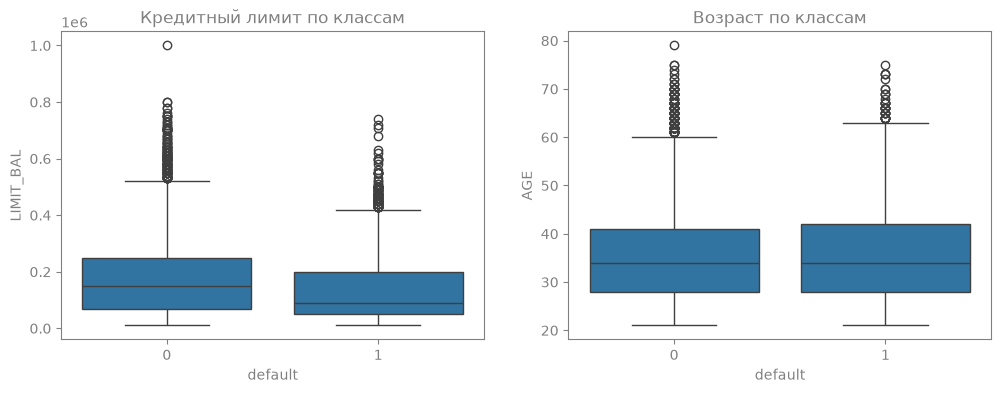

,LIMIT_BAL,AGE
default,,
0,150000.0,34.0
1,90000.0,34.0


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=data, x="default", y="LIMIT_BAL", ax=axes[0])
axes[0].set_title("Кредитный лимит по классам")
sns.boxplot(data=data, x="default", y="AGE", ax=axes[1])
axes[1].set_title("Возраст по классам")
plt.show()
data.groupby("default")[["LIMIT_BAL", "AGE"]].median()

Медианный лимит у клиентов с дефолтом 90000, без дефолта — 150000. Медианный возраст в обоих классах 34 года, связь с возрастом проверяем по группам далее.

Считаем корреляцию Спирмена признаков с целевой переменной: суммы сильно скошены, и связь может быть монотонной, но не линейной.

In [14]:
correlation = data.corr(method="spearman")["default"].drop("default").sort_values(key=abs, ascending=False)
correlation.round(3).to_frame()

,default
PAY_0,0.292
PAY_2,0.217
PAY_3,0.195
PAY_4,0.174
LIMIT_BAL,-0.170
PAY_AMT1,-0.160
PAY_5,0.159
PAY_AMT2,-0.151
PAY_6,0.143
PAY_AMT3,-0.139


Сильнее всего с дефолтом связаны статусы платежей, и чем ближе месяц, тем сильнее связь. Лимит и суммы платежей связаны отрицательно. У сумм счетов и возраста корреляция по модулю не больше 0.025, поэтому из счёта делаем относительный признак — долю использованного лимита.

## 6. Подготовка признаков

Добавляем агрегаты истории платежей: максимальную просрочку PAY_MAX, число месяцев с просрочкой PAY_DELAY_MONTHS, средние счёт и платёж BILL_MEAN и PAY_AMT_MEAN, загрузку лимита UTILIZATION и долю погашения счёта PAY_RATIO. Возраст делим на группы AGE_BIN. Функция build_features стоит первым шагом Pipeline, поэтому API принимает исходные признаки.

In [15]:
features = build_features.build_features(data)
new_features = ["PAY_MAX", "PAY_DELAY_MONTHS", "BILL_MEAN", "PAY_AMT_MEAN", "UTILIZATION", "PAY_RATIO"]
features[new_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
PAY_MAX,30000.0,0.439,1.345,-2.000,0.000,0.000,2.000,8.000
PAY_DELAY_MONTHS,30000.0,0.834,1.554,0.000,0.000,0.000,1.000,6.000
BILL_MEAN,30000.0,44976.945,63260.722,-56043.167,4781.333,21051.833,57104.417,877313.833
PAY_AMT_MEAN,30000.0,5275.232,10137.946,0.000,1113.292,2397.167,5583.917,627344.333
UTILIZATION,30000.0,0.424,0.411,-0.620,0.022,0.314,0.830,6.455
PAY_RATIO,28929.0,0.487,5.607,0.000,0.043,0.095,0.623,797.000


PAY_RATIO не определён у клиентов без положительного долга, эти NaN в Pipeline заполняются медианой. UTILIZATION бывает отрицательным при отрицательном счёте и больше единицы, когда счёт больше лимита.

Сравниваем корреляцию новых признаков с целевой переменной.

In [16]:
features[new_features + ["PAY_0", "LIMIT_BAL"]].corrwith(features["default"], method="spearman").sort_values(key=abs, ascending=False).round(3).to_frame("spearman")

,spearman
PAY_DELAY_MONTHS,0.388
PAY_MAX,0.321
PAY_0,0.292
PAY_AMT_MEAN,-0.174
LIMIT_BAL,-0.170
PAY_RATIO,-0.135
UTILIZATION,0.073
BILL_MEAN,-0.027


PAY_DELAY_MONTHS (0.388) и PAY_MAX (0.321) связаны с дефолтом сильнее PAY_0 (0.292). PAY_AMT_MEAN немного сильнее отдельных PAY_AMT, UTILIZATION сильнее BILL_AMT1.

Смотрим долю клиентов с дефолтом по числу месяцев с просрочкой и по возрастным группам.

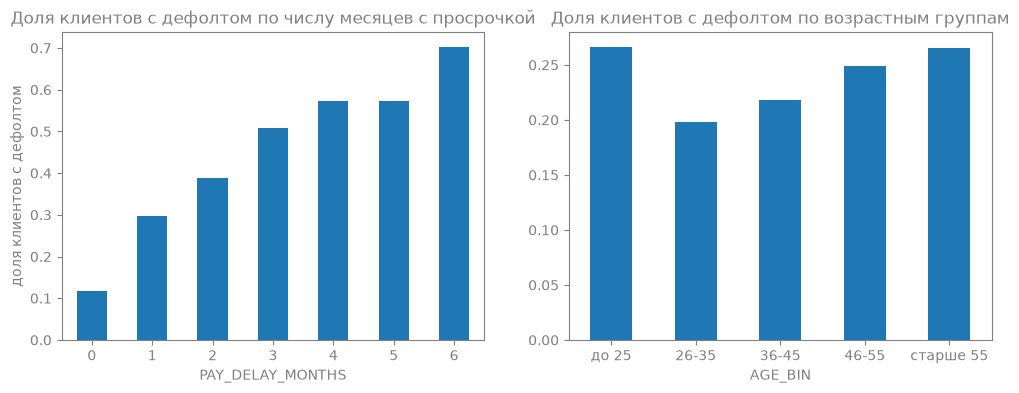

PAY_DELAY_MONTHS
0    0.117
1    0.298
2    0.388
3    0.509
4    0.573
5    0.574
6    0.703
            mean   size
AGE_BIN                
до 25      0.267   3871
26-35      0.198  12938
36-45      0.218   8522
46-55      0.249   3825
старше 55  0.265    844


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
features.groupby("PAY_DELAY_MONTHS")["default"].mean().plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Доля клиентов с дефолтом по числу месяцев с просрочкой")
axes[0].set_ylabel("доля клиентов с дефолтом")
age_order = build_features.AGE_LABELS
features.groupby("AGE_BIN")["default"].mean().reindex(age_order).plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Доля клиентов с дефолтом по возрастным группам")
plt.show()
print(features.groupby("PAY_DELAY_MONTHS")["default"].mean().round(3).to_string())
print(features.groupby("AGE_BIN")["default"].agg(["mean", "size"]).reindex(age_order).round(3).to_string())

Доля клиентов с дефолтом растёт с числом месяцев просрочки: от 0.117 без просрочек до 0.703 при шести месяцах. По возрасту зависимость U-образная: 0.198 в группе 26-35, 0.267 и 0.265 у самых молодых и самых старших. Корреляция Спирмена её не видит (0.005), поэтому передаём в модель и AGE, и AGE_BIN.

## 7. Выводы

1. Все столбцы числовые, NaN нет, ID уникален. 35 пар одинаковых без учёта ID строк оставляем.
2. Очистка в src/data/make_dataset.py: удаляем ID, переименовываем целевую переменную в default, коды EDUCATION 0, 5, 6 объединяем с 4, код MARRIAGE 0 — с 3.
3. Правила Great Expectations в src/data/validation.py: состав столбцов, NaN, типы, уникальный ID, LIMIT_BAL больше нуля, AGE от 18 до 100, коды SEX, EDUCATION и MARRIAGE, статусы платежей от -2 до 9, PAY_AMT не меньше нуля, целевая переменная 0 или 1.
4. Дефолт у 22.1% клиентов: делим выборку со стратификацией, модели сравниваем по ROC-AUC, порог подбираем по F1.
5. Сильнее всего с дефолтом связаны новые признаки PAY_DELAY_MONTHS (0.388) и PAY_MAX (0.321). AGE_BIN показывает U-образную зависимость от возраста.